# Преамбула

Предложенный набор данных содержит данные 49 штатов США по состоянию на 1950 г.:
- **State**: название штата
- **Ocean**: близость к морю
- **Lat**: широта
- **Long**: долгота
- **Mort**: смертность от рака кожи (количество смертей на 10 млн. населения)

# Задание 1

Необходимо научиться предсказывать значение смертности от рака кожи по значению [широты](https://ru.wikipedia.org/wiki/Широта).

1.   Загрузить датасет по адресу https://online.stat.psu.edu/stat462/sites/onlinecourses.science.psu.edu.stat462/files/data/skincancer/index.txt (Подсказка: для корректного прочтения файла используйте в функции read_csv аргумент sep="\s+")
2.   Отобразить краткую информацию о датасете
3.   Построить график зависимости смертности от широты, подписать график и оси координат
4.   Обучить модель линейной регрессии и визуализировать на графике зависимости смертности от широты прямую, харатеризующую обученную модель линейной регрессии
5.   Предоставить возможность пользователю ввести в поле ввода значение широты и вывести предсказанное значение смертности








In [42]:
#url = 'https://online.stat.psu.edu/stat462/sites/onlinecourses.science.psu.edu.stat462/files/data/skincancer/index.txt'

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

In [39]:
df = pd.read_csv("skincancer.txt", sep=r"\s+")
df.head()

,State,Lat,Mort,Ocean,Long
0,Alabama,33.0,219,1,87.0
1,Arizona,34.5,160,0,112.0
2,Arkansas,35.0,170,0,92.5
3,California,37.5,182,1,119.5
4,Colorado,39.0,149,0,105.5


#### **Краткая информация о датасете**

In [46]:
print(df.info())
print()
print(df.describe().round(1))
print()
print(df.isnull().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 49 entries, 0 to 48
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   State   49 non-null     object 
 1   Lat     49 non-null     float64
 2   Mort    49 non-null     int64  
 3   Ocean   49 non-null     int64  
 4   Long    49 non-null     float64
dtypes: float64(2), int64(2), object(1)
memory usage: 2.0+ KB
None

        Lat   Mort  Ocean   Long
count  49.0   49.0   49.0   49.0
mean   39.5  152.9    0.4   90.9
std     4.6   33.4    0.5   14.9
min    28.0   86.0    0.0   69.0
25%    36.0  128.0    0.0   78.5
50%    39.5  147.0    0.0   89.5
75%    43.0  178.0    1.0  100.0
max    47.5  229.0    1.0  121.0

State    0
Lat      0
Mort     0
Ocean    0
Long     0
dtype: int64


#### **График зависимости смертности от широты**

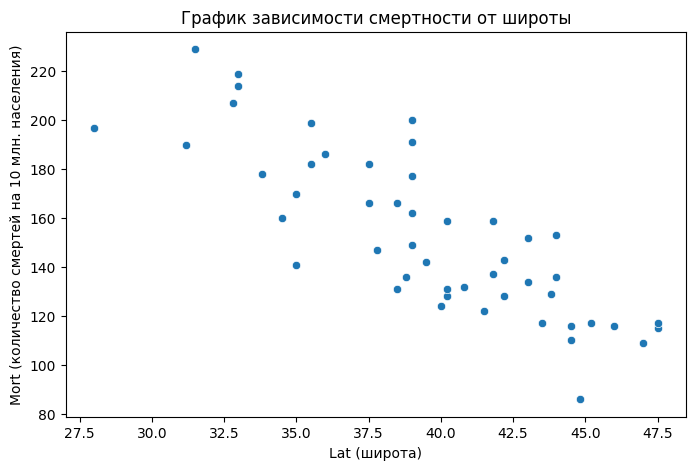

In [43]:
plt.figure(figsize=(8, 5))
sns.scatterplot(x="Lat", y="Mort", data=df)
plt.title("График зависимости смертности от широты")
plt.xlabel("Lat (широта)")
plt.ylabel("Mort (количество смертей на 10 млн. населения)")
plt.show()

#### **Обучение модели линейной регрессии**

(датасет слишком мал для разделения на тестовую и обучающую выборки)

In [47]:
X = df[["Lat"]]
y = df["Mort"]

model = LinearRegression()
model.fit(X, y)

LinearRegression()

In [60]:
print(f"Уравнение прямой: Mort = {model.intercept_.round(2)} + ({model.coef_[0].round(2)})*Lat")

Уравнение прямой: Mort = 389.19 + (-5.98)*Lat


**Визуализация**

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


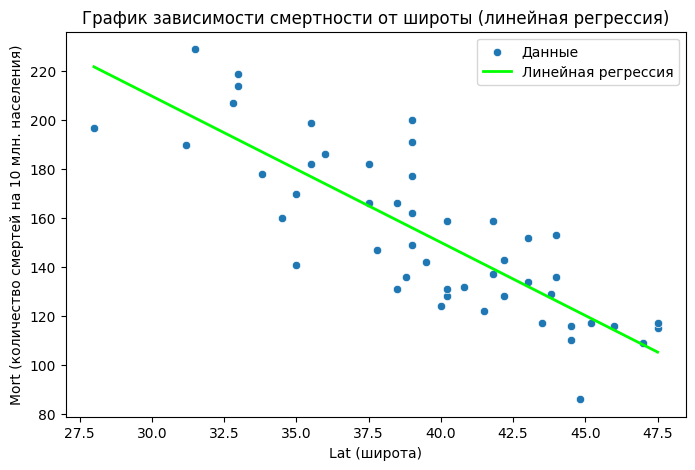

In [71]:
plt.figure(figsize=(8, 5))
sns.scatterplot(x="Lat", y="Mort", data=df, label="Данные")
x_line = np.linspace(df["Lat"].min(), df["Lat"].max(), 100).reshape(-1, 1)
y_line = model.predict(x_line)
plt.plot(x_line, y_line, color="lime", linewidth=2, label="Линейная регрессия")
plt.title("График зависимости смертности от широты (линейная регрессия)")
plt.xlabel("Lat (широта)")
plt.ylabel("Mort (количество смертей на 10 млн. населения)")
plt.legend()
plt.show()

#### **Пользовательский ввод**

In [83]:
lat_input = float(input("Введите значение широты: ").strip())
mort1_prediction = model.predict([[lat_input]])[0]
print(f"Предсказанная смертность: {round(mort1_prediction)} чел. на 10 млн. чел.")

Введите значение широты: 56
Предсказанная смертность: 54 чел. на 10 млн. чел.


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


# Задание 2

Необходимо разработать программу, работающую по следующему алгоритму:
1. Запросить у пользователя адрес в США (без указания страны)
2. Получить при помощи функции get_geo_object географический объект по указанному адресу, извлечь из него данные широты
3. Использовать данные широты чтобы предсказать возможную смертность. Вывести на экран итоговое сообщение (см. пример).Смертность округлить до целых.

**Пример**:

Ввод пользователя:
```
2661 Brown St, Napa, CA 94558
```
Итоговое сообщение:
```
Адрес: Brown Street, Napa, Napa County, California, 94558, United States  
Предсказанная смертность: 160 чел. на 10 млн. чел.
```

In [ ]:
# объявление функции get_geo_object и пример работы с ней
import requests
import json
import re

def get_geo_object(query_string):
  """
  Находит географический объект в США по адресу

  Аргументы
  ----------
  query_string : str
      Строка адреса. Возможны разделители в виде пробелов и запятых

  Возвращает
  ----------
  response.url : str
      Сформированная строка запроса к API geocode.maps.co
  response.json() : [{}]
      Список словарей географических объектов
  """
  GEO_URL = 'https://geocode.maps.co/search?'
  # query_string = re.sub(r'[\s,]+', '+', query_string)  # замена в строке поиска символы запятой и пробела на символ плюс

  params = {
        'q': query_string,
        'api_key': '6ae3bdadd9a57142965105djg3eee6c'
  }

  response = requests.get(GEO_URL, params=params)
  return response.url, response.json()

query = '1001 Van Ness Ave, San Francisco, CA 94109' # строка адреса в США
url, response = get_geo_object(query)
help(get_geo_object)
print(f'Request URL: { url }')
print(json.dumps(response, indent=1))

In [97]:
address_input = input("Введите адрес в США без указания страны: ").strip()

address_url, address_response = get_geo_object(address_input)
print(address_url)

geo = address_response[0]
lat = float(geo["lat"])
mort2_prediction = model.predict([[lat]])[0]
print(f"Предсказанная смертность: {round(mort2_prediction)} чел. на 10 млн. чел.")

Введите адрес в США без указания страны: 2661 Brown St, Napa, CA 94558
https://geocode.maps.co/search?q=2661+Brown+St%2C+Napa%2C+CA+94558&api_key=6ae3bdadd9a57142965105djg3eee6c
Предсказанная смертность: 160 чел. на 10 млн. чел.


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


# Контрольные вопросы

## Вопрос 1:
Приведите примеры (2-3) проблем, которые могут быть решены при помощи регрессии?

## Вопрос 2:
Сколько параметров в уравнении линейной регрессии? Опишите их смысл.

## Вопрос 3:
Для чего применяются библиотеки requests и re?
